# 04 - Đánh giá, so sánh và phân tích lỗi
Notebook này đọc kết quả do `python src/run_experiments.py` sinh ra trong `results/` và `reports/figures/`.

In [1]:
import sys
sys.path.append("../src")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.model_selection import GridSearchCV, cross_validate

from data import load_data, split_data, get_cv, TARGET, RANDOM_STATE
from models import make_pipeline, MODELS, MODEL_NAMES, DEFAULT_PARAMS, PARAM_GRIDS
from evaluate import evaluate

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = Path("../results"); FIG = Path("../reports/figures")
info = json.load(open(RES / 'run_info.json', encoding='utf-8'))
print(json.dumps(info, ensure_ascii=False, indent=1))

{
 "random_state": 42,
 "test_size": 0.2,
 "cv": "StratifiedKFold(5, shuffle=True, random_state=42)",
 "scoring": "f1_macro",
 "n_train": 3539,
 "n_test": 885,
 "class_counts_train": {
  "Graduate": 1767,
  "Dropout": 1137,
  "Enrolled": 635
 },
 "class_counts_test": {
  "Graduate": 442,
  "Dropout": 284,
  "Enrolled": 159
 },
 "best_by_cv": {
  "model": "dt",
  "flow": "B1",
  "params": "{\"class_weight\": \"balanced\", \"criterion\": \"entropy\", \"max_depth\": 5, \"min_samples_leaf\": 5}",
  "cv_f1_macro": 0.6869667744741546,
  "test_f1_macro": 0.6627056411563094,
  "test_acc": 0.6847457627118644
 },
 "python": "3.13.18",
 "sklearn": "1.9.1",
 "pandas": "3.0.5",
 "numpy": "2.5.3",
 "runtime_seconds": 116
}


## 1. Bảng kết quả tổng hợp

In [2]:
final = pd.read_csv(RES / "final.csv")
cols = ["stage", "model", "flow", "cv_f1_macro", "cv_std", "test_acc", "test_f1_macro", "recall_Dropout", "f1_Enrolled"]
final[cols].round(3)

,stage,model,flow,cv_f1_macro,cv_std,test_acc,test_f1_macro,recall_Dropout,f1_Enrolled
0,default,knn,A,0.610,0.025,0.668,0.573,0.676,0.244
1,default,dt,A,0.627,0.009,0.697,0.639,0.697,0.413
2,default,nb,A,0.575,0.022,0.659,0.558,0.665,0.219
3,default,knn,B1,0.639,0.021,0.703,0.620,0.729,0.313
4,default,dt,B1,0.628,0.010,0.673,0.608,0.697,0.351
5,default,nb,B1,0.658,0.021,0.715,0.647,0.676,0.395
6,default,knn,B2,0.617,0.020,0.702,0.619,0.690,0.337
7,default,dt,B2,0.621,0.018,0.701,0.637,0.732,0.393
8,default,nb,B2,0.283,0.018,0.311,0.302,0.366,0.348
9,default,knn,B,0.651,0.017,0.739,0.664,0.725,0.404


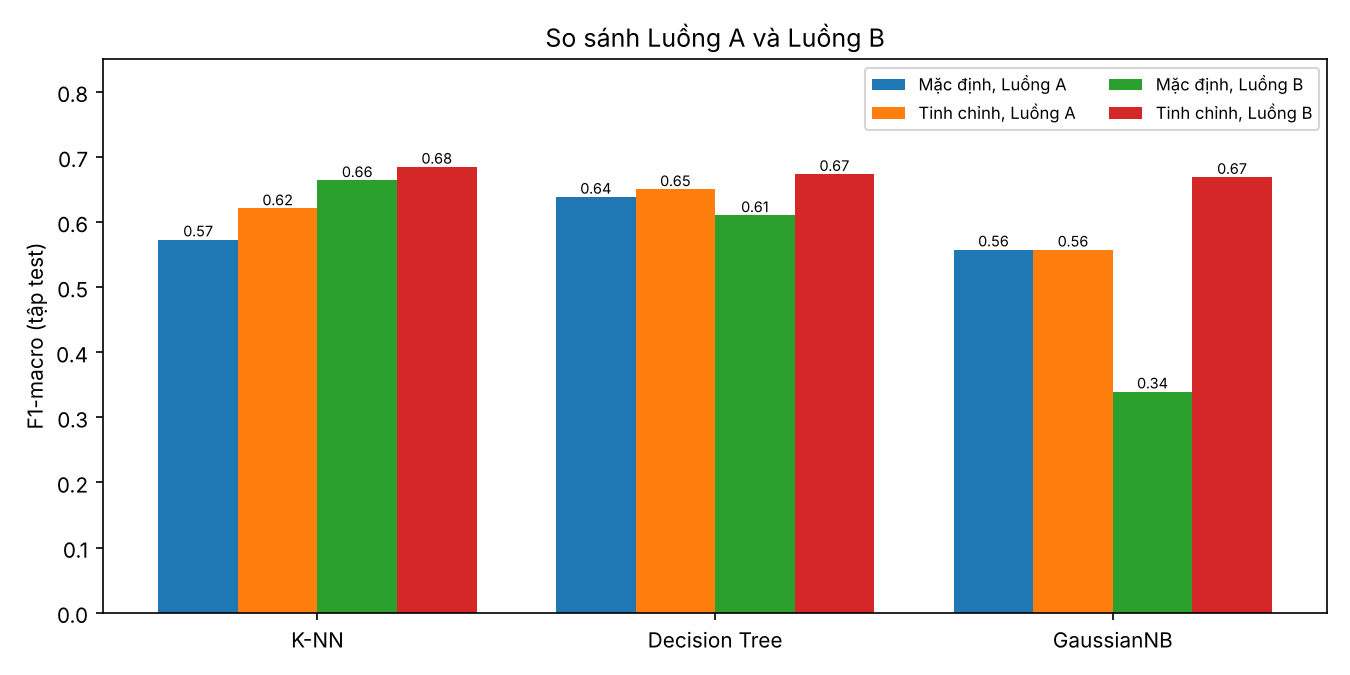

In [3]:
display(Image(filename=str(FIG / "res_01_compare_AB.png")))

## 2. Mô hình tốt nhất (chọn theo CV) và Confusion Matrix

{'model': 'dt', 'flow': 'B1', 'params': '{"class_weight": "balanced", "criterion": "entropy", "max_depth": 5, "min_samples_leaf": 5}', 'cv_f1_macro': 0.6869667744741546, 'test_f1_macro': 0.6627056411563094, 'test_acc': 0.6847457627118644}


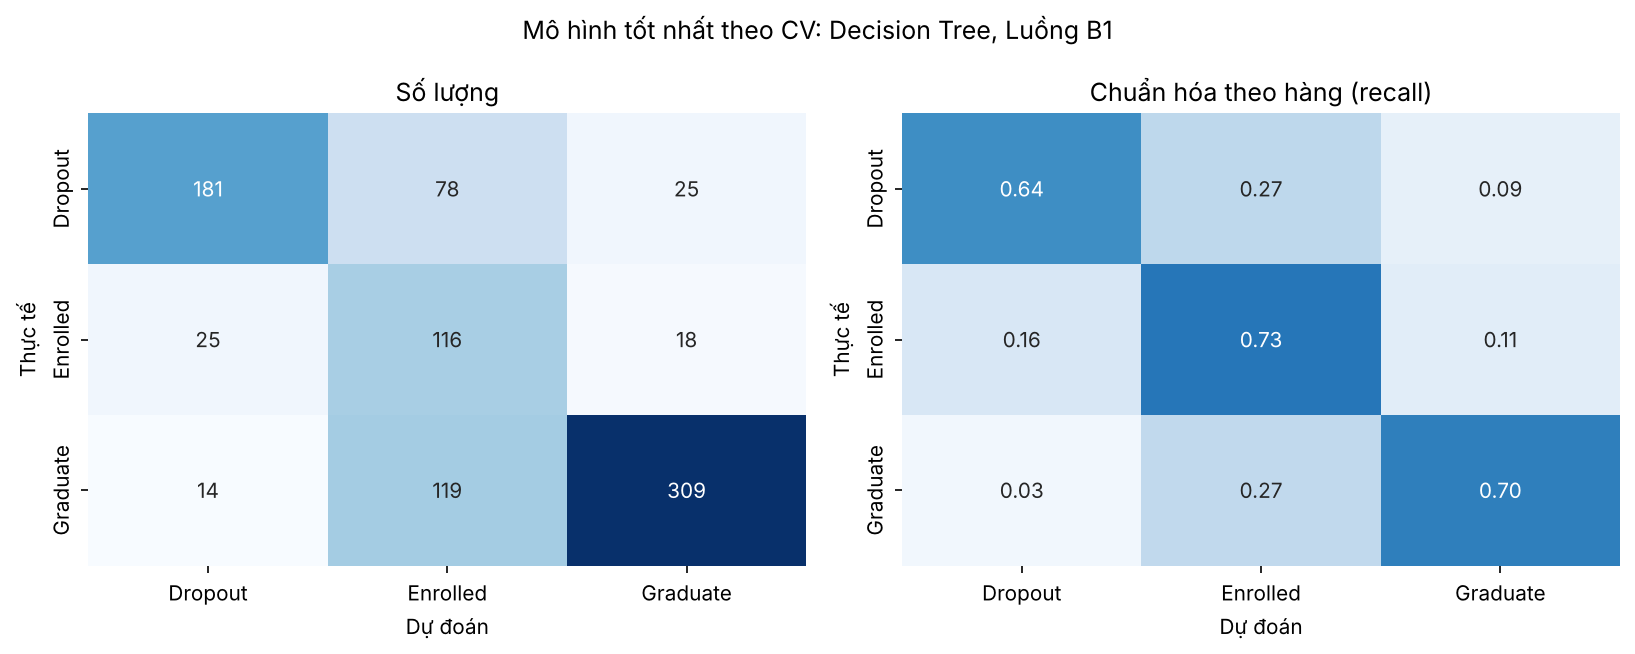

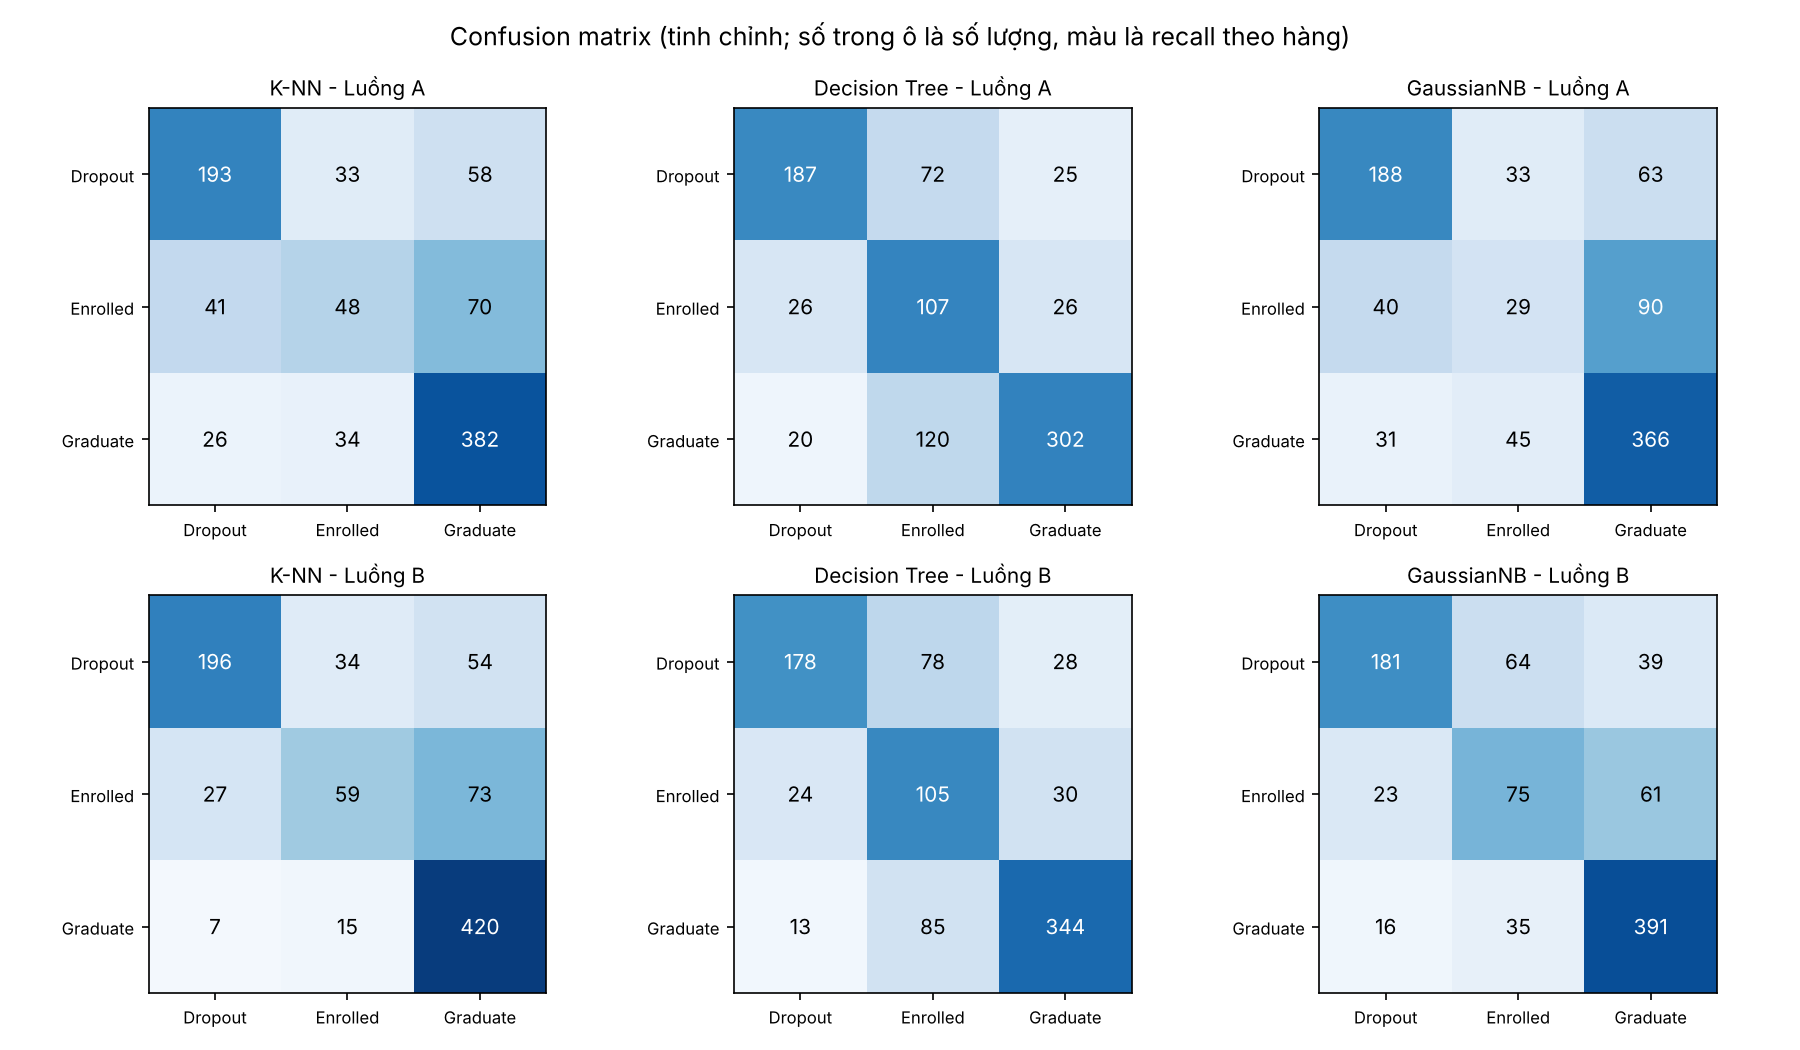

In [4]:
print(info["best_by_cv"])
display(Image(filename=str(FIG / "res_04_confusion_best.png")))
display(Image(filename=str(FIG / "res_05_confusion_grid.png")))

## 3. Phân tích lỗi

In [5]:
pair = pd.read_csv(RES / "confusion_best.csv", index_col=0)
print("Hàng = thực tế, cột = dự đoán"); display(pair)
prof = pd.read_csv(RES / "error_profile.csv")
prof.rename(columns={"true": "thực tế", "pred": "dự đoán"})

Hàng = thực tế, cột = dự đoán


,Dropout,Enrolled,Graduate
thuc_te,,,
Dropout,181,78,25
Enrolled,25,116,18
Graduate,14,119,309


,thực tế,dự đoán,n,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),approval_rate_2nd,Tuition fees up to date,Scholarship holder,Debtor,Age at enrollment,Admission grade
0,Dropout,Dropout,181,1.49,0.81,3.18,0.13,0.54,0.05,0.25,27.67,124.32
1,Dropout,Enrolled,78,4.03,3.54,11.46,0.55,0.92,0.08,0.18,23.06,124.87
2,Dropout,Graduate,25,5.04,5.16,10.94,0.78,0.88,0.16,0.12,23.96,136.61
3,Enrolled,Dropout,25,2.48,1.72,6.35,0.31,0.84,0.20,0.12,23.16,123.53
4,Enrolled,Enrolled,116,4.19,3.95,11.92,0.66,0.97,0.15,0.12,22.41,125.79
5,Enrolled,Graduate,18,6.17,6.39,11.53,0.93,1.00,0.22,0.22,20.06,128.14
6,Graduate,Dropout,14,3.79,3.64,7.79,0.55,0.64,0.43,0.21,19.43,132.66
7,Graduate,Enrolled,119,5.65,5.11,12.19,0.80,1.00,0.20,0.03,22.26,126.11
8,Graduate,Graduate,309,6.76,6.82,13.24,0.96,0.99,0.42,0.07,21.94,130.19


In [6]:
# Các mẫu sai mà mô hình tự tin nhất (xác suất dự đoán cao nhưng sai)
err = pd.read_csv(RES / "error_cases.csv", index_col=0)
print("Tổng số mẫu sai:", len(err), "/", info["n_test"])
err.head(10).round(2)

Tổng số mẫu sai: 279 / 885


,true,pred,conf_pred,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),approval_rate_2nd,Tuition fees up to date,Scholarship holder,Debtor,Age at enrollment,Admission grade,Course,Gender
502,Enrolled,Dropout,1.00,5,4,10.83,0.67,0,0,0,18,132.0,9070,0
186,Enrolled,Dropout,1.00,8,4,10.00,0.67,0,0,1,21,126.6,9238,0
3676,Graduate,Dropout,1.00,9,4,11.25,0.40,0,0,1,22,119.9,9238,0
1820,Enrolled,Dropout,1.00,5,3,11.67,0.50,0,0,0,19,130.0,9085,0
3993,Graduate,Dropout,0.94,6,5,11.80,0.83,0,1,1,20,137.9,9773,0
4213,Graduate,Dropout,0.94,5,5,11.40,0.83,0,1,0,20,130.0,9238,0
3174,Enrolled,Graduate,0.93,5,6,10.83,1.00,1,1,0,19,120.2,9238,0
3281,Dropout,Graduate,0.93,12,8,12.88,1.00,0,0,0,59,140.0,8014,0
2282,Dropout,Enrolled,0.88,5,5,10.00,0.83,0,0,1,21,121.0,9254,1
2265,Enrolled,Dropout,0.87,5,4,14.80,0.67,0,0,0,21,104.6,9085,1


**Ghi chú để viết báo cáo:** xem `error_profile.csv`. Nhóm Dropout bị đoán thành Enrolled có hồ sơ học tập giống sinh viên đang học bình thường (số môn đạt và tỷ lệ đạt học kỳ 2 cao, đóng học phí đúng hạn), nên khó tách chỉ bằng dữ liệu học tập; nhóm Graduate bị đoán thành Enrolled có tỷ lệ đạt học kỳ 2 thấp hơn nhóm Graduate đoán đúng. Cần đọc các số thật trong file khi viết.

## 4. Cây quyết định nông và độ quan trọng đặc trưng

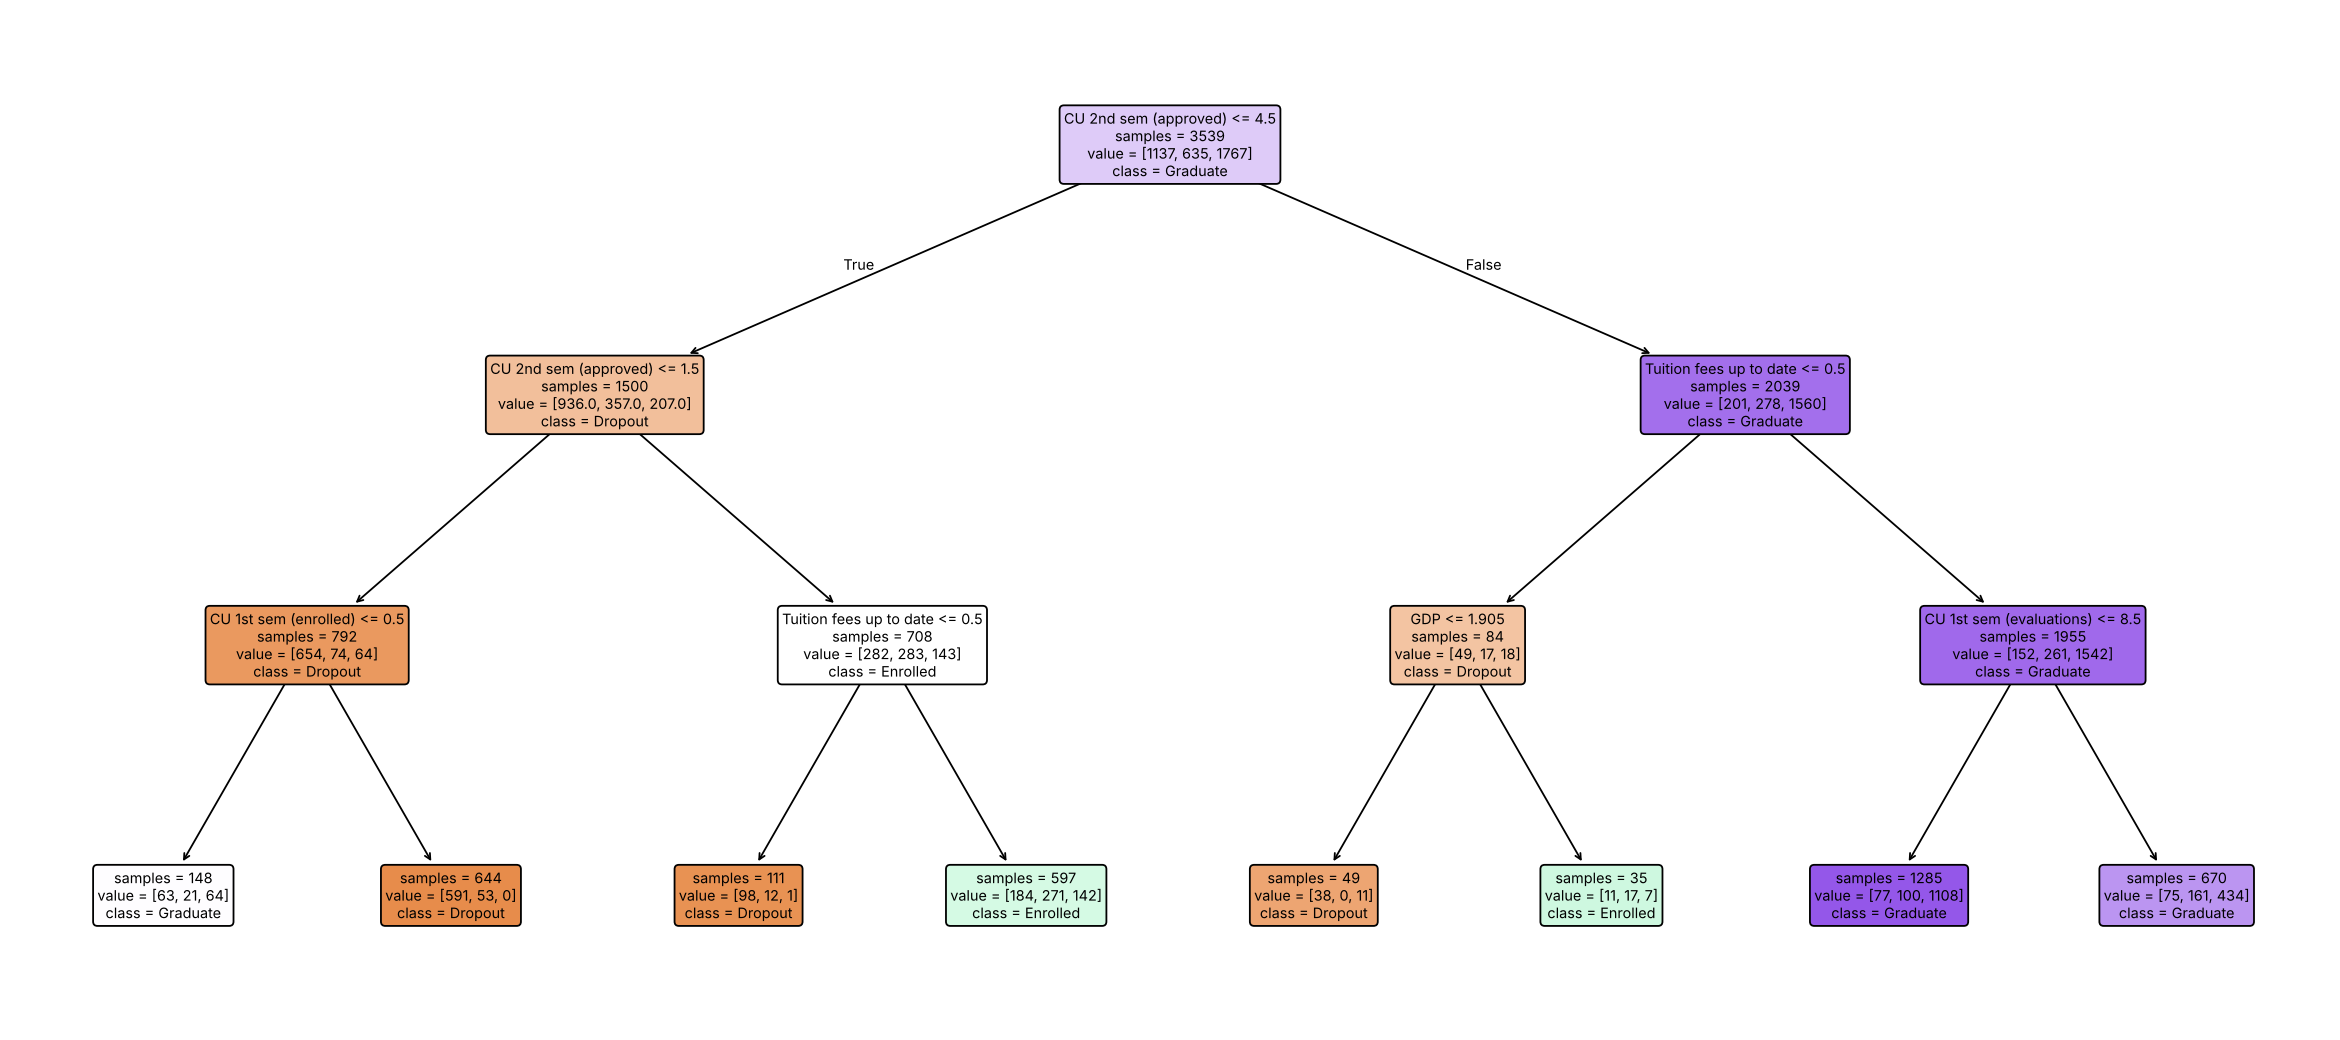

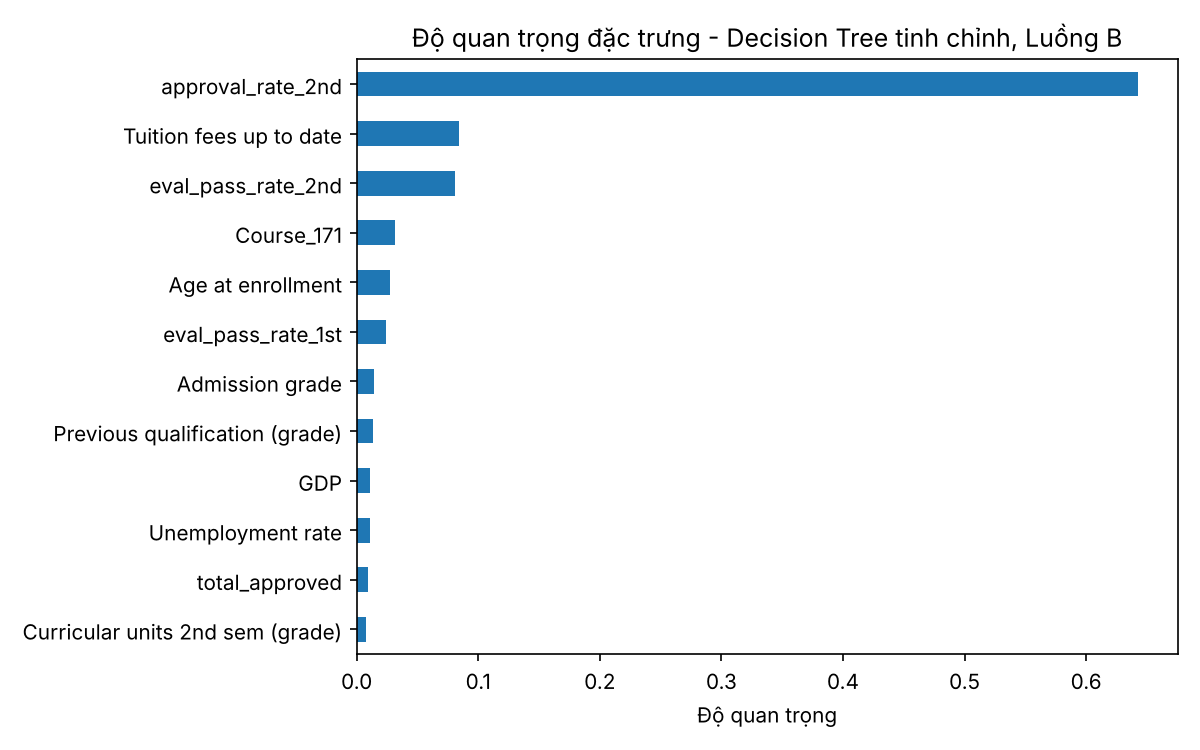

In [7]:
display(Image(filename=str(FIG / "res_06_tree_depth3.png")))
display(Image(filename=str(FIG / "res_07_importance_dtB.png")))

## 5. Cấu hình cảnh báo sớm (bỏ toàn bộ cột học kỳ 2)

In [8]:
ew = pd.read_csv(RES / "early_warning.csv")
full = pd.read_csv(RES / "tuned_models.csv")
m = ew.merge(full, on=["model", "flow"], suffixes=("_early", "_full"))
m["giảm F1-macro"] = (m.test_f1_macro_full - m.test_f1_macro_early).round(3)
m[["model", "flow", "test_f1_macro_early", "test_f1_macro_full", "giảm F1-macro", "recall_Dropout_early", "recall_Dropout_full"]].round(3)

,model,flow,test_f1_macro_early,test_f1_macro_full,giảm F1-macro,recall_Dropout_early,recall_Dropout_full
0,knn,A,0.570,0.621,0.051,0.616,0.680
1,knn,B,0.636,0.685,0.049,0.644,0.690
2,dt,A,0.627,0.650,0.023,0.613,0.658
3,dt,B,0.634,0.673,0.039,0.669,0.627
4,nb,A,0.497,0.557,0.061,0.637,0.662
5,nb,B,0.611,0.669,0.058,0.634,0.637


## 6. Dùng mô hình đã lưu để dự đoán một sinh viên
`models/best_model.joblib` là Pipeline hoàn chỉnh (tiền xử lý + mô hình), nhận DataFrame có đúng các cột gốc.

In [9]:
import joblib
df = load_data()
Xtr, Xte, ytr, yte = split_data(df)
best = joblib.load("../models/best_model.joblib")
sample = Xte.iloc[[0]]
print(dict(zip(best.classes_, best.predict_proba(sample)[0].round(3))), "| thực tế:", yte.iloc[0])

{'Dropout': np.float64(0.287), 'Enrolled': np.float64(0.0), 'Graduate': np.float64(0.713)} | thực tế: Graduate
